In [1]:
#Linear model over non linear data
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from scipy import stats 
print("Success")

Success


In [2]:
x=np.random.normal(0,2,100)
noise=np.random.normal(0,0.05,100)
y=2.5+x-(0.5*x*x)+noise
df=pd.DataFrame({"x":x,"y":y})

In [3]:
#dataframe trai and test split
from sklearn.model_selection import train_test_split 

xtrain1,xtest1,ytrain1,ytest1=train_test_split(df[['x']],df['y'],test_size=20,random_state=42)
print(xtrain1.shape)
print(xtest1.shape)

(80, 1)
(20, 1)


In [4]:
from sklearn import linear_model
lr1=linear_model.LinearRegression()
lr1.fit(xtrain1,ytrain1)

yp1=lr1.predict(xtrain1)#training
yp2=lr1.predict(xtest1)#testing 


In [5]:
from sklearn import metrics
MSE1=metrics.mean_squared_error(ytrain1,yp1)
print("MSE for training",MSE1);
print("R2: for training :",metrics.r2_score(ytrain1,yp1))

MSE for training 4.50614038534164
R2: for training : 0.46631380084715446


In [6]:
MSE2=metrics.mean_squared_error(ytest1,yp2)
print("MSE for testing",MSE2);
print("R2: for testing :",metrics.r2_score(ytest1,yp2))

MSE for testing 5.581971797039382
R2: for testing : 0.5605782398680367


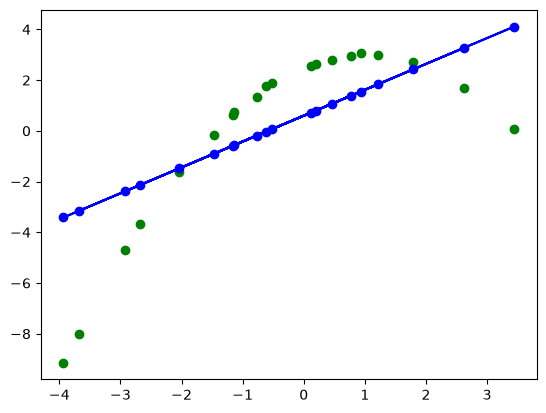

In [7]:
plt.scatter(xtest1,ytest1,c="g",label='Actual Data')
plt.scatter(xtest1,yp2,c="b",label='PRedictd')
plt.plot(xtest1,yp2,c="b",label='Linear Regression line')

<Axes: >

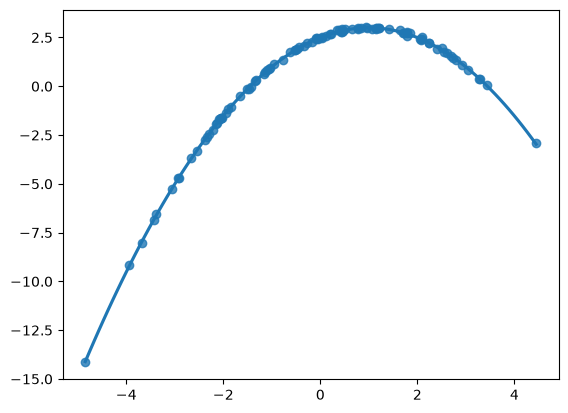

In [8]:
import seaborn as sns
sns.regplot(data=df,x=x,y=y,order=2)

In [9]:
from sklearn.preprocessing import PolynomialFeatures
poly_feat=PolynomialFeatures(degree=3,include_bias=False)
xpoly=poly_feat.fit_transform(df[['x']])

In [10]:
xtrain2,xtest2,ytrain2,ytest2=train_test_split(xpoly,y,test_size=0.2,random_state=42)

In [11]:
lr2=linear_model.LinearRegression()
lr2.fit(xtrain2,ytrain2)
yp3=lr2.predict(xtrain2)
yp4=lr2.predict(xtest2)

MSE3=metrics.mean_squared_error(ytrain2,yp3)
print("MSE for training",MSE3);
print("R2: for training :",metrics.r2_score(ytrain2,yp3))

MSE for training 0.002225082905777655
R2: for training : 0.9997364715838309


In [12]:
MSE4=metrics.mean_squared_error(ytest2,yp4)
print("MSE for training",MSE4);
print("R2: for training :",metrics.r2_score(ytest2,yp4))

MSE for training 0.002846729265822732
R2: for training : 0.9997759009127796


In [13]:
k_values = range(1, 20) 
r2_scores = [] 
mse_train = []  # Added to track training error
mse_test = []   # Renamed from MSE_ for clarity

for k in k_values: 
    poly_f = PolynomialFeatures(degree=k, include_bias=False) 
    xpoly = poly_f.fit_transform(df[['x']]) 
    xtrain, xtest, ytrain, ytest = train_test_split(xpoly, y, test_size=0.2, random_state=42) 
    
    model = linear_model.LinearRegression() 
    model.fit(xtrain, ytrain) 
    
    # Predict on both train and test sets
    y_pred_train = model.predict(xtrain)
    y_pred_test = model.predict(xtest) 
    
    # Calculate and store metrics
    score = metrics.r2_score(ytest, y_pred_test) 
    r2_scores.append(score)
    
    mse_train.append(metrics.mean_squared_error(ytrain, y_pred_train)) 
    mse_test.append(metrics.mean_squared_error(ytest, y_pred_test))

# Clean print loop using enumerate to prevent index errors
for idx, degree in enumerate(k_values):
    print(f"Degree {degree} \tR2: {r2_scores[idx]:.4f}")
    print(f"\tMSE Train: {mse_train[idx]:.4f}")
    print(f"\tMSE Test:  {mse_test[idx]:.4f}\n")

Degree 1 	R2: 0.5606
	MSE Train: 4.5061
	MSE Test:  5.5820

Degree 2 	R2: 0.9998
	MSE Train: 0.0022
	MSE Test:  0.0028

Degree 3 	R2: 0.9998
	MSE Train: 0.0022
	MSE Test:  0.0028

Degree 4 	R2: 0.9998
	MSE Train: 0.0022
	MSE Test:  0.0030

Degree 5 	R2: 0.9998
	MSE Train: 0.0022
	MSE Test:  0.0030

Degree 6 	R2: 0.9998
	MSE Train: 0.0022
	MSE Test:  0.0030

Degree 7 	R2: 0.9997
	MSE Train: 0.0021
	MSE Test:  0.0034

Degree 8 	R2: 0.9997
	MSE Train: 0.0021
	MSE Test:  0.0043

Degree 9 	R2: 0.9996
	MSE Train: 0.0021
	MSE Test:  0.0049

Degree 10 	R2: 0.9074
	MSE Train: 0.0410
	MSE Test:  1.1769

Degree 11 	R2: 0.6644
	MSE Train: 0.2753
	MSE Test:  4.2636

Degree 12 	R2: -3.6660
	MSE Train: 1.1783
	MSE Test:  59.2717

Degree 13 	R2: -8.2111
	MSE Train: 1.5953
	MSE Test:  117.0087

Degree 14 	R2: -13.4176
	MSE Train: 1.8139
	MSE Test:  183.1466

Degree 15 	R2: -9.2313
	MSE Train: 2.5106
	MSE Test:  129.9675

Degree 16 	R2: -14.0273
	MSE Train: 2.7994
	MSE Test:  190.8911

Degree 17 	R2: -5

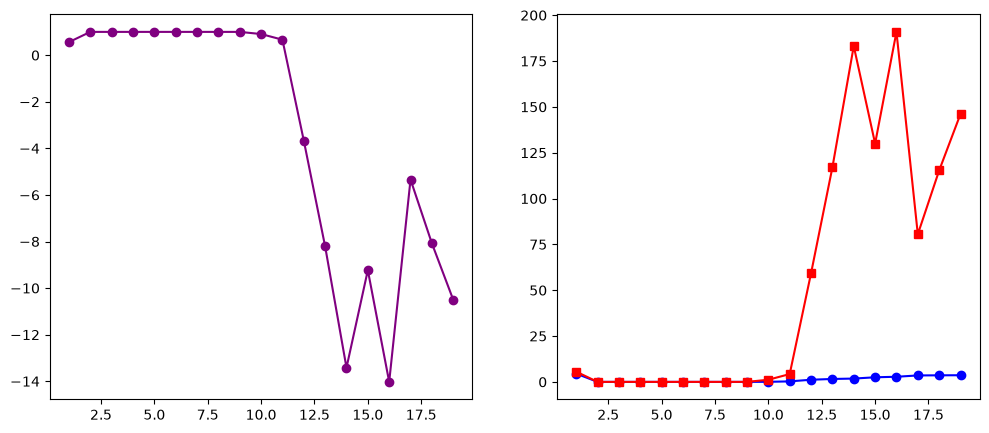

In [18]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(k_values, r2_scores, marker='o', color='purple')
plt.subplot(1, 2, 2)
plt.plot(k_values, mse_train, marker='o', color='blue')
plt.plot(k_values, mse_test, marker='s', color='red')